In [ ]:
import  pandas as pd


In [2]:
df=pd.read_csv(r'C:\DEPI poject#2\data.csv')

In [3]:
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [6]:
df.duplicated().sum()

np.int64(715)

In [8]:
df.isna().sum()

Make                    0
Model                   0
Year                    0
Engine Fuel Type        3
Engine HP              69
Engine Cylinders       30
Transmission Type       0
Driven_Wheels           0
Number of Doors         6
Market Category      3742
Vehicle Size            0
Vehicle Style           0
highway MPG             0
city mpg                0
Popularity              0
MSRP                    0
dtype: int64

In [10]:
(df['Market Category'].isna().sum()/df['Market Category'].count())*100

np.float64(45.79050416054821)

In [13]:
# Categorical
df['Engine Fuel Type'].fillna(df['Engine Fuel Type'].mode()[0], inplace=True)

# Numerical
df['Engine HP'].fillna(df['Engine HP'].median(), inplace=True)
df['Engine Cylinders'].fillna(df['Engine Cylinders'].median(), inplace=True)
df['Number of Doors'].fillna(df['Number of Doors'].median(), inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_4048\1527181465.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Engine Fuel Type'].fillna(df['Engine Fuel Type'].mode()[0], inplace=True)
C:\Users\DELL\AppData\Local\Temp\ipykernel_4048\1527181465.py:5: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series t

0        2.0
1        2.0
2        2.0
3        2.0
4        2.0
        ... 
11909    4.0
11910    4.0
11911    4.0
11912    4.0
11913    4.0
Name: Number of Doors, Length: 11914, dtype: float64

In [ ]:

#df['Market Category'].fillna('Unknown', inplace=True)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11914 non-null  str    
 1   Model              11914 non-null  str    
 2   Year               11914 non-null  int64  
 3   Engine Fuel Type   11911 non-null  str    
 4   Engine HP          11845 non-null  float64
 5   Engine Cylinders   11884 non-null  float64
 6   Transmission Type  11914 non-null  str    
 7   Driven_Wheels      11914 non-null  str    
 8   Number of Doors    11908 non-null  float64
 9   Market Category    8172 non-null   str    
 10  Vehicle Size       11914 non-null  str    
 11  Vehicle Style      11914 non-null  str    
 12  highway MPG        11914 non-null  int64  
 13  city mpg           11914 non-null  int64  
 14  Popularity         11914 non-null  int64  
 15  MSRP               11914 non-null  int64  
dtypes: float64(3), int64(5), str(8)
m

In [12]:
df.describe()

,Year,Engine HP,Engine Cylinders,Number of Doors,highway MPG,city mpg,Popularity,MSRP
count,11914.000000,11845.00000,11884.000000,11908.000000,11914.000000,11914.000000,11914.000000,1.191400e+04
mean,2010.384338,249.38607,5.628829,3.436093,26.637485,19.733255,1554.911197,4.059474e+04
std,7.579740,109.19187,1.780559,0.881315,8.863001,8.987798,1441.855347,6.010910e+04
min,1990.000000,55.00000,0.000000,2.000000,12.000000,7.000000,2.000000,2.000000e+03
25%,2007.000000,170.00000,4.000000,2.000000,22.000000,16.000000,549.000000,2.100000e+04
50%,2015.000000,227.00000,6.000000,4.000000,26.000000,18.000000,1385.000000,2.999500e+04
75%,2016.000000,300.00000,6.000000,4.000000,30.000000,22.000000,2009.000000,4.223125e+04
max,2017.000000,1001.00000,16.000000,4.000000,354.000000,137.000000,5657.000000,2.065902e+06


In [15]:
for col in df.select_dtypes(include='object').columns:
    print(col, df[col].nunique())

Make 48
Model 915
Engine Fuel Type 10
Transmission Type 5
Driven_Wheels 4
Market Category 71
Vehicle Size 3
Vehicle Style 16


C:\Users\DELL\AppData\Local\Temp\ipykernel_4048\753239467.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


In [16]:
df.drop_duplicates(inplace=True)

In [17]:
df.reset_index(drop=True, inplace=True)

In [18]:
print("New Shape:", df.shape)

New Shape: (11199, 16)


In [19]:
print("Engine Cylinders:")
print(df['Engine Cylinders'].value_counts().sort_index())

print("Number of Doors:")
print(df['Number of Doors'].value_counts().sort_index())

print("Vehicle Years:")
print(df['Year'].value_counts().sort_index())

print("MSRP:")
print(df['MSRP'].describe())

Engine Cylinders:
Engine Cylinders
0.0       56
3.0       30
4.0     4362
5.0      169
6.0     4291
8.0     1965
10.0      65
12.0     228
16.0       3
Name: count, dtype: int64
Number of Doors:
Number of Doors
2.0    2877
3.0     356
4.0    7960
Name: count, dtype: int64
Vehicle Years:
Year
1990      77
1991     103
1992     127
1993     160
1994     129
1995     117
1996     115
1997     166
1998     145
1999     114
2000     115
2001     168
2002     205
2003     238
2004     235
2005     213
2006     194
2007     334
2008     322
2009     364
2010     281
2011     284
2012     351
2013     325
2014     554
2015    2065
2016    2073
2017    1625
Name: count, dtype: int64
MSRP:
count    1.119900e+04
mean     4.192593e+04
std      6.153505e+04
min      2.000000e+03
25%      2.159950e+04
50%      3.067500e+04
75%      4.303250e+04
max      2.065902e+06
Name: MSRP, dtype: float64


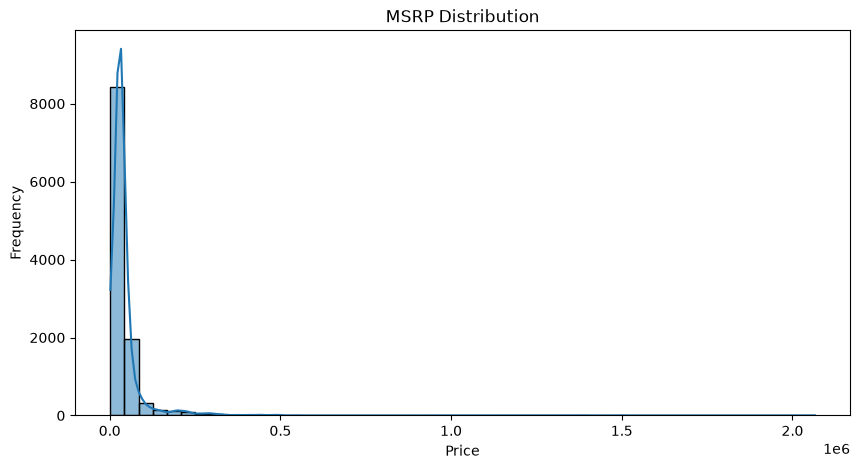

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))

sns.histplot(df['MSRP'], bins=50, kde=True)

plt.title('MSRP Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')

plt.show()

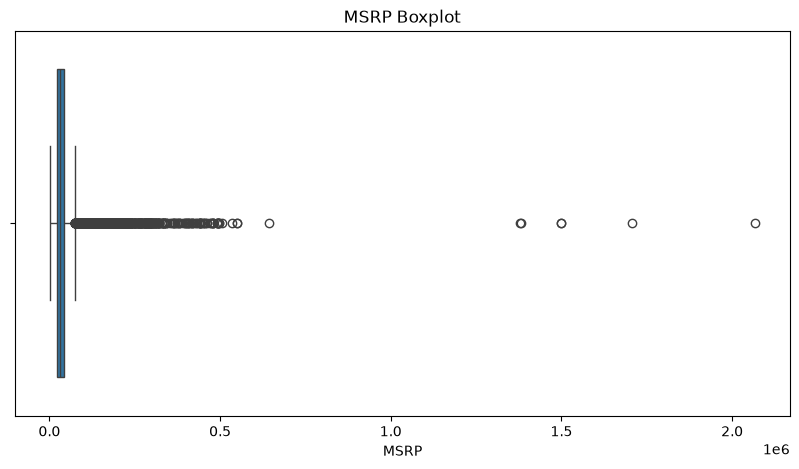

In [21]:
plt.figure(figsize=(10,5))

sns.boxplot(x=df['MSRP'])

plt.title('MSRP Boxplot')

plt.show()

In [22]:
df.nlargest(20, 'MSRP')[['Make', 'Model', 'Year', 'Engine HP', 'MSRP']]

,Make,Model,Year,Engine HP,MSRP
10661,Bugatti,Veyron 16.4,2008,1001.0,2065902
10663,Bugatti,Veyron 16.4,2009,1001.0,1705769
7973,Lamborghini,Reventon,2008,650.0,1500000
10662,Bugatti,Veyron 16.4,2008,1001.0,1500000
6001,Maybach,Landaulet,2012,620.0,1382750
6000,Maybach,Landaulet,2011,620.0,1380000
3798,Ferrari,Enzo,2003,660.0,643330
1584,Lamborghini,Aventador,2014,720.0,548800
1588,Lamborghini,Aventador,2015,720.0,548800
1591,Lamborghini,Aventador,2016,750.0,535500


In [23]:
print("Skewness:", df['MSRP'].skew())

print("Median:", df['MSRP'].median())

print("Mean:", df['MSRP'].mean())

print("99th Percentile:", df['MSRP'].quantile(0.99))

Skewness: 11.609709303878942
Median: 30675.0
Mean: 41925.92713635146
99th Percentile: 290009.2200000002


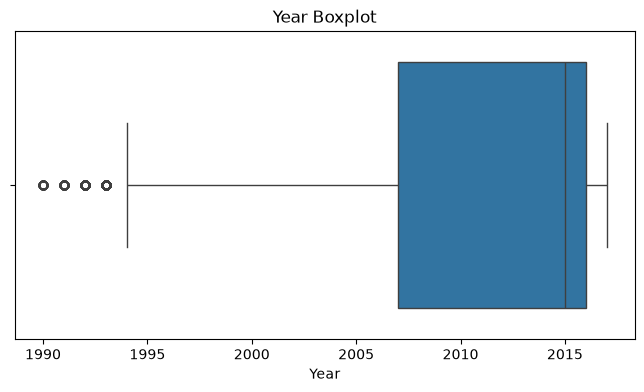

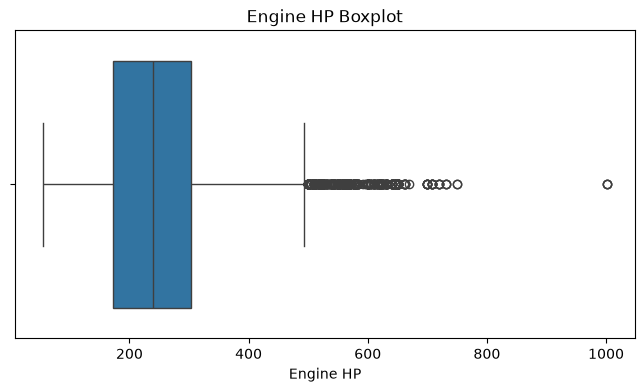

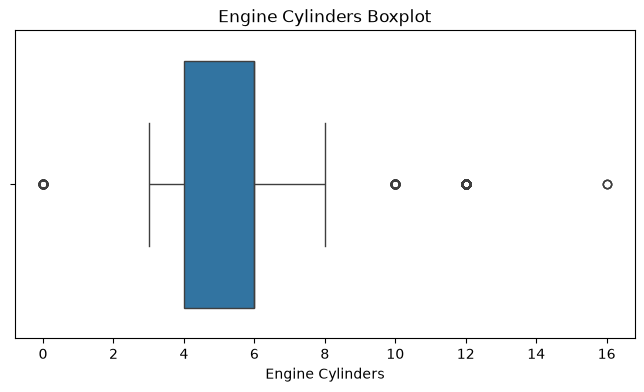

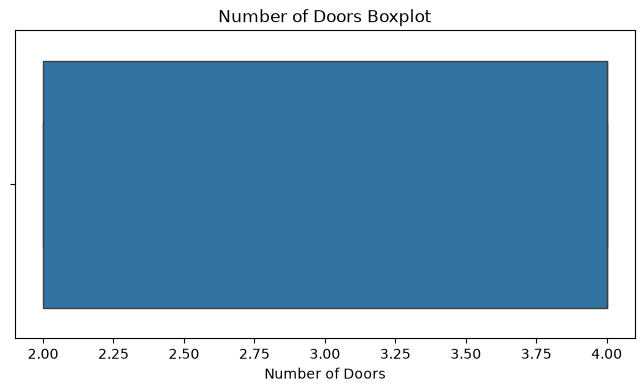

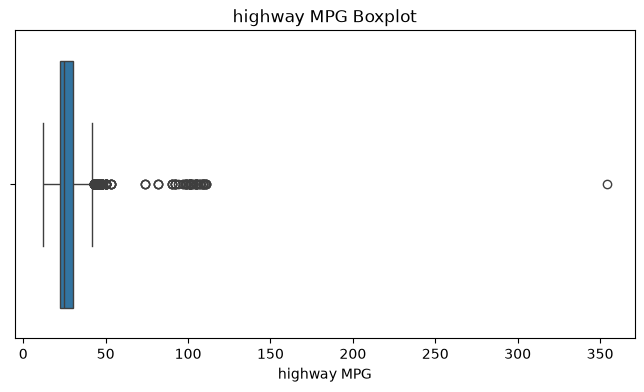

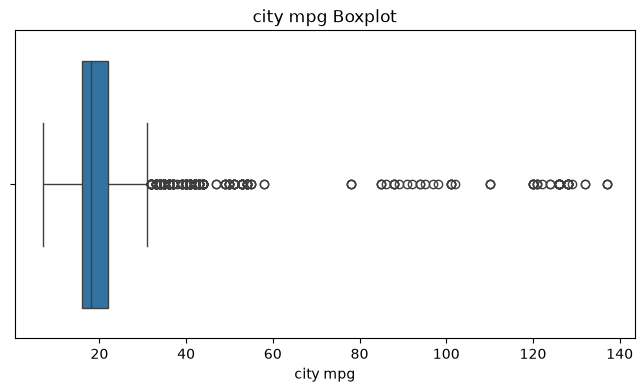

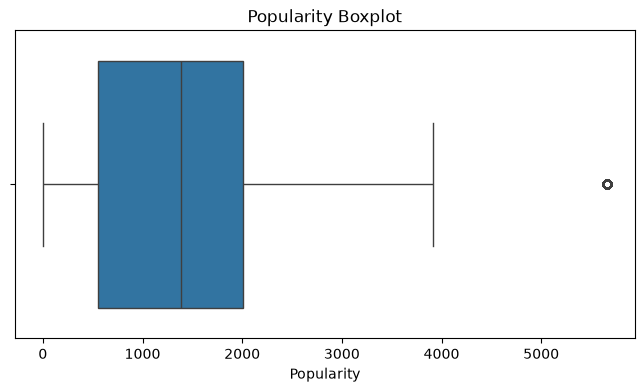

In [24]:
numerical_cols = [
    'Year',
    'Engine HP',
    'Engine Cylinders',
    'Number of Doors',
    'highway MPG',
    'city mpg',
    'Popularity'
]

for col in numerical_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f'{col} Boxplot')
    plt.show()

In [25]:
cols = ['Engine HP', 'highway MPG', 'city mpg']

for col in cols:
    print(f'\nHighest values in {col}')

    print(
        df.nlargest(10, col)[
            ['Make', 'Model', 'Year', col, 'MSRP']
        ]
    )


Highest values in Engine HP
              Make           Model  Year  Engine HP     MSRP
10661      Bugatti     Veyron 16.4  2008     1001.0  2065902
10662      Bugatti     Veyron 16.4  2008     1001.0  1500000
10663      Bugatti     Veyron 16.4  2009     1001.0  1705769
1591   Lamborghini       Aventador  2016      750.0   535500
1592   Lamborghini       Aventador  2016      750.0   490700
4412       Ferrari  F12 Berlinetta  2013      731.0   315888
4413       Ferrari  F12 Berlinetta  2014      731.0   315888
4414       Ferrari  F12 Berlinetta  2015      731.0   319995
1584   Lamborghini       Aventador  2014      720.0   548800
1585   Lamborghini       Aventador  2014      720.0   497650

Highest values in highway MPG
           Make     Model  Year  highway MPG   MSRP
1083       Audi        A6  2017          354  51600
5505        BMW        i3  2015          111  42400
5506        BMW        i3  2016          111  42400
5507        BMW        i3  2017          111  42400
1865  Che

In [26]:
print(df[['Engine HP', 'highway MPG', 'city mpg']].describe())

          Engine HP   highway MPG      city mpg
count  11130.000000  11199.000000  11199.000000
mean     253.388859     26.610590     19.731851
std      110.150938      8.977641      9.177555
min       55.000000     12.000000      7.000000
25%      172.000000     22.000000     16.000000
50%      239.000000     25.000000     18.000000
75%      303.000000     30.000000     22.000000
max     1001.000000    354.000000    137.000000


In [27]:


print(df.nlargest(15, 'city mpg')[
    ['Make', 'Model', 'Year', 'city mpg', 'MSRP']
])

print(df.nlargest(15, 'highway MPG')[
    ['Make', 'Model', 'Year', 'highway MPG', 'MSRP']
])

# Check missing values again
print(df[['Engine HP', 'highway MPG', 'city mpg']].isna().sum())

            Make     Model  Year  city mpg   MSRP
5505         BMW        i3  2015       137  42400
5506         BMW        i3  2016       137  42400
5507         BMW        i3  2017       137  42400
4470       Honda    Fit EV  2013       132  36625
4471       Honda    Fit EV  2014       132  36625
5508         BMW        i3  2017       129  43600
1865   Chevrolet   Bolt EV  2017       128  40905
1866   Chevrolet   Bolt EV  2017       128  36620
9262   Chevrolet  Spark EV  2014       128  26685
9263   Chevrolet  Spark EV  2014       128  27010
9264   Chevrolet  Spark EV  2015       128  25170
9265   Chevrolet  Spark EV  2015       128  25560
9266   Chevrolet  Spark EV  2016       128  25510
9267   Chevrolet  Spark EV  2016       128  25120
3507  Volkswagen    e-Golf  2015       126  33450
           Make     Model  Year  highway MPG   MSRP
1083       Audi        A6  2017          354  51600
5505        BMW        i3  2015          111  42400
5506        BMW        i3  2016          111

In [28]:
df[df['highway MPG'] > 150][[
    'Make',
    'Model',
    'Year',
    'Engine Fuel Type',
    'Engine HP',
    'city mpg',
    'highway MPG',
    'MSRP'
]]

,Make,Model,Year,Engine Fuel Type,Engine HP,city mpg,highway MPG,MSRP
1083,Audi,A6,2017,premium unleaded (recommended),252.0,24,354,51600


In [30]:
import numpy as np
df.loc[
    (df['Make'] == 'Audi') &
    (df['Model'] == 'A6') &
    (df['Year'] == 2017) &
    (df['highway MPG'] == 354),
    'highway MPG'
] = np.nan
df['highway MPG'] = df['highway MPG'].fillna(
    df['highway MPG'].median()
)

In [31]:
print(df['Popularity'].describe())
print("Skewness:", df['Popularity'].skew())

count    11199.000000
mean      1558.483347
std       1445.668872
min          2.000000
25%        549.000000
50%       1385.000000
75%       2009.000000
max       5657.000000
Name: Popularity, dtype: float64
Skewness: 1.6283047966008912


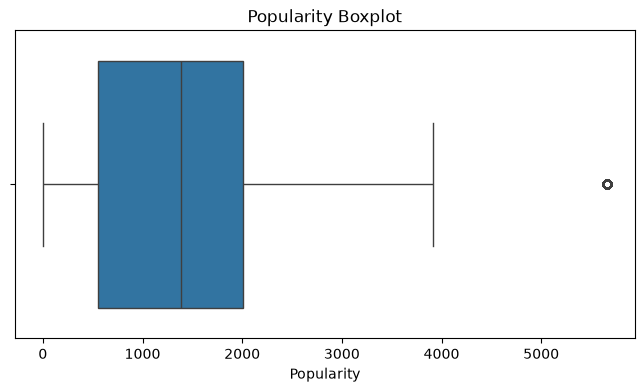

In [32]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df['Popularity'])

plt.title('Popularity Boxplot')

plt.show()

In [33]:
df.nlargest(15, 'Popularity')[[
    'Make', 'Model', 'Year', 'Popularity', 'MSRP'
]]

,Make,Model,Year,Popularity,MSRP
1294,Ford,Aerostar,1995,5657,2000
1295,Ford,Aerostar,1995,5657,2000
1296,Ford,Aerostar,1995,5657,2000
1297,Ford,Aerostar,1995,5657,2000
1298,Ford,Aerostar,1996,5657,2000
1299,Ford,Aerostar,1996,5657,2000
1300,Ford,Aerostar,1996,5657,2000
1301,Ford,Aerostar,1996,5657,2000
1302,Ford,Aerostar,1997,5657,2000
1303,Ford,Aerostar,1997,5657,2000


In [34]:
cat_cols = df.select_dtypes(include=['object', 'str']).columns

for col in cat_cols:
    print(f'\n{col}')
    print(df[col].value_counts().head(10))


Make
Make
Chevrolet     1083
Ford           825
Toyota         719
Volkswagen     568
Nissan         551
Dodge          529
GMC            482
Honda          433
Mazda          412
Cadillac       396
Name: count, dtype: int64

Model
Model
Silverado 1500     156
Tundra             129
F-150              126
Sierra 1500         90
Frontier            76
Accord              74
Tacoma              71
Civic               66
Ram Pickup 1500     62
Corvette            60
Name: count, dtype: int64

Engine Fuel Type
Engine Fuel Type
regular unleaded                                6658
premium unleaded (required)                     1956
premium unleaded (recommended)                  1392
flex-fuel (unleaded/E85)                         887
diesel                                           150
electric                                          66
flex-fuel (premium unleaded required/E85)         53
flex-fuel (premium unleaded recommended/E85)      26
flex-fuel (unleaded/natural gas)             

In [35]:
print("Negative prices:", (df['MSRP'] < 0).sum())
print("Zero prices:", (df['MSRP'] == 0).sum())
print("Missing values:", df.isna().sum().sum())

Negative prices: 0
Zero prices: 0
Missing values: 3484


In [36]:
df.isna().sum()

Make                    0
Model                   0
Year                    0
Engine Fuel Type        3
Engine HP              69
Engine Cylinders       30
Transmission Type       0
Driven_Wheels           0
Number of Doors         6
Market Category      3376
Vehicle Size            0
Vehicle Style           0
highway MPG             0
city mpg                0
Popularity              0
MSRP                    0
dtype: int64

In [37]:
# Categorical columns
df['Engine Fuel Type'] = df['Engine Fuel Type'].fillna(
    df['Engine Fuel Type'].mode()[0]
)

# Numerical columns
df['Engine HP'] = df['Engine HP'].fillna(
    df['Engine HP'].median()
)

df['Engine Cylinders'] = df['Engine Cylinders'].fillna(
    df['Engine Cylinders'].median()
)

df['Number of Doors'] = df['Number of Doors'].fillna(
    df['Number of Doors'].median()
)

# Market Category
df['Market Category'] = df['Market Category'].fillna('Unknown')

In [38]:
df.isna().sum()

Make                 0
Model                0
Year                 0
Engine Fuel Type     0
Engine HP            0
Engine Cylinders     0
Transmission Type    0
Driven_Wheels        0
Number of Doors      0
Market Category      0
Vehicle Size         0
Vehicle Style        0
highway MPG          0
city mpg             0
Popularity           0
MSRP                 0
dtype: int64

cat colum spac


In [39]:
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    print(f"\n{col}")
    print(df[col].unique()[:20])


Make
<StringArray>
[          'BMW',          'Audi',          'FIAT', 'Mercedes-Benz',
      'Chrysler',        'Nissan',         'Volvo',         'Mazda',
    'Mitsubishi',       'Ferrari',    'Alfa Romeo',        'Toyota',
       'McLaren',       'Maybach',       'Pontiac',       'Porsche',
          'Saab',           'GMC',       'Hyundai',      'Plymouth']
Length: 20, dtype: str

Model
<StringArray>
[           '1 Series M',              '1 Series',                   '100',
            '124 Spider',             '190-Class',              '2 Series',
                   '200',                 '200SX',                 '240SX',
                   '240',                     '2', '3 Series Gran Turismo',
              '3 Series',             '300-Class',                '3000GT',
                   '300',                  '300M',                 '300ZX',
                   '323',             '350-Class']
Length: 20, dtype: str

Engine Fuel Type
<StringArray>
[                 'premium un

C:\Users\DELL\AppData\Local\Temp\ipykernel_4048\3943783963.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns


In [40]:
for col in df.select_dtypes(include=['object', 'str']).columns:
    print(col, ":", df[col].nunique())

Make : 48
Model : 915
Engine Fuel Type : 10
Transmission Type : 5
Driven_Wheels : 4
Market Category : 72
Vehicle Size : 3
Vehicle Style : 16


In [43]:
df['Market Category'].value_counts().head(20)

Market Category
Unknown                                  3376
Crossover                                1075
Flex Fuel                                 855
Luxury                                    819
Luxury,Performance                        659
Hatchback                                 574
Performance                               520
Crossover,Luxury                          406
Luxury,High-Performance                   334
Exotic,High-Performance                   254
Factory Tuner,Luxury,High-Performance     215
Hatchback,Performance                     198
High-Performance                          198
Hybrid                                    121
Crossover,Luxury,Performance              112
Factory Tuner,High-Performance            104
Flex Fuel,Performance                      87
Factory Tuner,Performance                  84
Diesel                                     84
Exotic,Luxury,High-Performance             77
Name: count, dtype: int64

In [44]:
df['Model'] = df['Model'].map(
    {v: k for k, v in model_freq.items()}
)

In [46]:
X = df.drop('MSRP', axis=1)
y = df['MSRP']

In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [48]:
model_freq = X_train['Model'].value_counts(normalize=True)

X_train['Model'] = X_train['Model'].map(model_freq).fillna(0)

X_test['Model'] = X_test['Model'].map(model_freq).fillna(0)

In [49]:
print(X_train.shape)
print(X_test.shape)

(8959, 89)
(2240, 89)


In [50]:
print(X_train.dtypes.value_counts())
print(X_train.select_dtypes(include=['object', 'str']).columns.tolist())
print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())

int64      83
float64     5
str         1
Name: count, dtype: int64
['Market Category']
0
0


In [42]:
categorical_cols = [
    'Make',
    'Engine Fuel Type',
    'Transmission Type',
    'Driven_Wheels',
    'Vehicle Size',
    'Vehicle Style'
]

df = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

In [51]:
market_train = X_train['Market Category'].str.get_dummies(sep=',')
market_test = X_test['Market Category'].str.get_dummies(sep=',')

market_test = market_test.reindex(
    columns=market_train.columns,
    fill_value=0
)

market_train.columns = ['Market_' + col for col in market_train.columns]
market_test.columns = ['Market_' + col for col in market_test.columns]

X_train = X_train.drop('Market Category', axis=1)
X_test = X_test.drop('Market Category', axis=1)

X_train = pd.concat([X_train, market_train], axis=1)
X_test = pd.concat([X_test, market_test], axis=1)

In [52]:
print(X_train.shape)
print(X_test.shape)

print(X_train.select_dtypes(include=['object', 'str']).columns)

(8959, 99)
(2240, 99)
Index([], dtype='str')


In [53]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [54]:
print(y_train.shape)
print(y_test.shape)

print(y_train.isnull().sum())
print(y_test.isnull().sum())

(8959,)
(2240,)
0
0


training and ev

In [55]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

In [56]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    'Extra Trees': ExtraTreesRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

In [57]:
results = []

for name, model in models.items():

    if name in ['Linear Regression', 'Ridge']:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)

    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values('R2 Score', ascending=False))

               Model          MAE          RMSE  R2 Score
3        Extra Trees  3337.909873  11407.999250  0.973139
1              Ridge  9235.866817  18918.267421  0.926131
0  Linear Regression  9238.173151  18919.257890  0.926124
2      Random Forest  3647.405304  19877.151723  0.918453


In [58]:
best_model = ExtraTreesRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

best_model.fit(X_train, y_train)

train_pred = best_model.predict(X_train)
test_pred = best_model.predict(X_test)

print("Train R2:", r2_score(y_train, train_pred))
print("Test R2:", r2_score(y_test, test_pred))

print("Train MAE:", mean_absolute_error(y_train, train_pred))
print("Test MAE:", mean_absolute_error(y_test, test_pred))

Train R2: 0.9979114919642801
Test R2: 0.9731393418246094
Train MAE: 1280.3011491890186
Test MAE: 3337.909873357298


In [59]:
from sklearn.ensemble import ExtraTreesRegressor

models = {
    'Extra Trees 1': ExtraTreesRegressor(
        n_estimators=200,
        max_depth=25,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    'Extra Trees 2': ExtraTreesRegressor(
        n_estimators=200,
        max_depth=30,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),

    'Extra Trees 3': ExtraTreesRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=2,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    )
}

هنجرب كذا طريقه ممكن نحسن المودل او نقلل ال overfiting 

In [60]:
for name, model in models.items():

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    print("\n", name)

    print("Train R2:", r2_score(y_train, train_pred))
    print("Test R2:", r2_score(y_test, test_pred))

    print("Train MAE:", mean_absolute_error(y_train, train_pred))
    print("Test MAE:", mean_absolute_error(y_test, test_pred))


 Extra Trees 1
Train R2: 0.9672009407383158
Test R2: 0.8548348392386756
Train MAE: 1961.6953557400627
Test MAE: 3949.798289158335

 Extra Trees 2
Train R2: 0.9142345834454706
Test R2: 0.7801972133293178
Train MAE: 2563.177734218287
Test MAE: 4366.625735250581

 Extra Trees 3
Train R2: 0.9666628644506393
Test R2: 0.8579388453133079
Train MAE: 2005.3498129218667
Test MAE: 3948.3090620197854


 نشوف لو في data leak
 

In [61]:
print("Train duplicates:", X_train.duplicated().sum())
print("Test duplicates:", X_test.duplicated().sum())

Train duplicates: 3220
Test duplicates: 306


In [62]:
train_test_overlap = pd.merge(
    X_train,
    X_test,
    how='inner'
)

print("Common feature rows:", len(train_test_overlap))

Common feature rows: 2659


In [63]:
train_check = X_train.copy()
train_check['MSRP'] = y_train

test_check = X_test.copy()
test_check['MSRP'] = y_test

common = pd.merge(
    train_check,
    test_check,
    how='inner'
)

print("Common rows including MSRP:", len(common))

Common rows including MSRP: 0


In [64]:
train_features = X_train.copy()
test_features = X_test.copy()

common_features = pd.merge(
    train_features,
    test_features,
    how='inner'
)

print("Common feature rows:", len(common_features))

Common feature rows: 2659


In [65]:
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("Train unique rows:", len(X_train.drop_duplicates()))
print("Test unique rows:", len(X_test.drop_duplicates()))

print("Train duplicate rows:", X_train.duplicated().sum())
print("Test duplicate rows:", X_test.duplicated().sum())

Train shape: (8959, 99)
Test shape: (2240, 99)
Train unique rows: 5739
Test unique rows: 1934
Train duplicate rows: 3220
Test duplicate rows: 306


In [66]:
train_check = X_train.copy()
train_check['MSRP'] = y_train.values

test_check = X_test.copy()
test_check['MSRP'] = y_test.values

merged = pd.merge(
    train_check,
    test_check,
    on=list(X_train.columns),
    suffixes=('_train', '_test')
)

print("Common feature rows:", len(merged))

print(
    "Same MSRP:",
    (merged['MSRP_train'] == merged['MSRP_test']).sum()
)

print(
    "Different MSRP:",
    (merged['MSRP_train'] != merged['MSRP_test']).sum()
)

Common feature rows: 2659
Same MSRP: 0
Different MSRP: 2659


In [67]:
print(merged[['MSRP_train', 'MSRP_test']].describe())

merged['Price_Difference'] = abs(
    merged['MSRP_train'] - merged['MSRP_test']
)

print(merged['Price_Difference'].describe())

          MSRP_train      MSRP_test
count    2659.000000    2659.000000
mean    36250.981948   36320.497932
std     26797.683724   27152.768067
min      2000.000000    2000.000000
25%     25235.000000   25380.000000
50%     31620.000000   32155.000000
75%     41080.000000   41105.000000
max    417825.000000  492425.000000
count     2659.000000
mean      4255.117337
std       5460.216328
min          2.000000
25%       1665.000000
50%       3100.000000
75%       5300.000000
max      79500.000000
Name: Price_Difference, dtype: float64


In [68]:
print(merged[
    ['MSRP_train', 'MSRP_test', 'Price_Difference']
].head(15))

    MSRP_train  MSRP_test  Price_Difference
0        41310      43620              2310
1        41310      37825              3485
2        25590      25585                 5
3        59855      55400              4455
4        26515      26465                50
5        33430      33100               330
6        68500      61250              7250
7        25065      25365               300
8        27435      28595              1160
9         2207       2268                61
10        2207       2265                58
11        2207       2529               322
12       41850      38565              3285
13       36935      35100              1835
14       25850      28630              2780


In [69]:
# Check repeated feature combinations in the original dataset

feature_cols = [col for col in df.columns if col != 'MSRP']

duplicate_groups = (
    df.groupby(feature_cols, dropna=False)['MSRP']
    .agg(['count', 'nunique', 'min', 'max', 'mean'])
    .reset_index()
)

repeated_groups = duplicate_groups[
    duplicate_groups['count'] > 1
]

print("Repeated groups:", len(repeated_groups))

print(
    "Groups with different prices:",
    (repeated_groups['nunique'] > 1).sum()
)

print(
    "Groups with identical prices:",
    (repeated_groups['nunique'] == 1).sum()
)

print(repeated_groups.sort_values(
    'count', ascending=False
).head(10))

Repeated groups: 2535
Groups with different prices: 2535
Groups with identical prices: 0
                Model  Year  Engine HP  Engine Cylinders  Number of Doors  \
840            Sienna  2017      296.0               6.0              4.0   
832            Sienna  2016      266.0               6.0              4.0   
824            Sienna  2015      266.0               6.0              4.0   
3640              XL7  2007      252.0               6.0              4.0   
3639              XL7  2007      252.0               6.0              4.0   
3042           Vitara  2006      250.0               6.0              4.0   
115   C/K 1500 Series  1998      200.0               6.0              2.0   
113   C/K 1500 Series  1998      200.0               6.0              2.0   
107   C/K 1500 Series  1997      200.0               6.0              2.0   
4499            Yaris  2010      227.0               6.0              4.0   

     Market Category  highway MPG  city mpg  Popularity  Make_A

In [70]:
print(repeated_groups['max'].describe())

count    2.535000e+03
mean     4.094664e+04
std      5.722709e+04
min      2.002000e+03
25%      2.498750e+04
50%      3.299500e+04
75%      4.370500e+04
max      2.065902e+06
Name: max, dtype: float64


In [71]:
repeated_groups['price_range'] = (
    repeated_groups['max'] - repeated_groups['min']
)

repeated_groups['price_range_pct'] = (
    repeated_groups['price_range'] /
    repeated_groups['mean'] * 100
)

print(repeated_groups['price_range_pct'].describe())

count    2535.000000
mean       13.903786
std         8.352165
min         0.097513
25%         7.749644
50%        12.166710
75%        19.022509
max        64.351885
Name: price_range_pct, dtype: float64


In [72]:
print(
    repeated_groups.sort_values(
        'price_range',
        ascending=False
    )[
        ['count', 'nunique', 'min', 'max',
         'mean', 'price_range', 'price_range_pct']
    ].head(15)
)

      count  nunique      min      max          mean  price_range  \
6016      2        2  1500000  2065902  1.782951e+06       565902   
1429      7        7   101995   186495  1.313093e+05        84500   
1419      5        5   100100   184105  1.336710e+05        84005   
1418      6        6   100100   184105  1.311600e+05        84005   
4209      2        2   417825   492425  4.551250e+05        74600   
4169      2        2   407400   480175  4.437875e+05        72775   
4125      2        2   402940   474990  4.389650e+05        72050   
6316      2        2   418950   470350  4.446500e+05        51400   
6315      2        2   379050   430450  4.047500e+05        51400   
6305      2        2   405500   456500  4.310000e+05        51000   
6310      2        2   372500   423500  3.980000e+05        51000   
6311      2        2   412000   463000  4.375000e+05        51000   
6306      2        2   455500   506500  4.810000e+05        51000   
6304      2        2   366000   41

In [73]:
top_groups = repeated_groups.sort_values(
    'price_range',
    ascending=False
).head(15)

for idx, row in top_groups.iterrows():
    print("\nModel:", row['Model'])
    print("Year:", row['Year'])
    print("Minimum Price:", row['min'])
    print("Maximum Price:", row['max'])
    print("Price Difference:", row['price_range'])


Model: Z8
Year: 2008
Minimum Price: 1500000
Maximum Price: 2065902
Price Difference: 565902

Model: Titan
Year: 2015
Minimum Price: 101995
Maximum Price: 186495
Price Difference: 84500

Model: Titan
Year: 2014
Minimum Price: 100100
Maximum Price: 184105
Price Difference: 84005

Model: Titan
Year: 2014
Minimum Price: 100100
Maximum Price: 184105
Price Difference: 84005

Model: XT5
Year: 2016
Minimum Price: 417825
Maximum Price: 492425
Price Difference: 74600

Model: XT5
Year: 2015
Minimum Price: 407400
Maximum Price: 480175
Price Difference: 72775

Model: XT5
Year: 2014
Minimum Price: 402940
Maximum Price: 474990
Price Difference: 72050

Model: ZDX
Year: 2012
Minimum Price: 418950
Maximum Price: 470350
Price Difference: 51400

Model: ZDX
Year: 2012
Minimum Price: 379050
Maximum Price: 430450
Price Difference: 51400

Model: ZDX
Year: 2010
Minimum Price: 405500
Maximum Price: 456500
Price Difference: 51000

Model: ZDX
Year: 2011
Minimum Price: 372500
Maximum Price: 423500
Price Differenc

In [74]:
print(df['MSRP'].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]
))

print("Skewness:", df['MSRP'].skew())

count    1.119900e+04
mean     4.192593e+04
std      6.153505e+04
min      2.000000e+03
1%       2.000000e+03
5%       2.000000e+03
25%      2.159950e+04
50%      3.067500e+04
75%      4.303250e+04
95%      1.120700e+05
99%      2.900092e+05
max      2.065902e+06
Name: MSRP, dtype: float64
Skewness: 11.609709303878942


In [75]:
# Inspect Z8
z8 = df[
    (df['Model'] == 'Z8') &
    (df['Year'] == 2008)
]

print(z8[['Model', 'Year', 'Engine HP',
          'Engine Cylinders', 'Number of Doors',
          'MSRP']].to_string(index=False))

# Inspect Titan
titan = df[
    (df['Model'] == 'Titan') &
    (df['Year'] == 2015)
]

print(titan[['Model', 'Year', 'Engine HP',
             'Engine Cylinders', 'Number of Doors',
             'MSRP']].to_string(index=False))

Model  Year  Engine HP  Engine Cylinders  Number of Doors    MSRP
   Z8  2008      264.0               6.0              4.0   25495
   Z8  2008      450.0               8.0              2.0  329990
   Z8  2008      320.0               8.0              4.0   50100
   Z8  2008      263.0               8.0              4.0   47315
   Z8  2008      300.0               8.0              4.0   48525
   Z8  2008      300.0               8.0              4.0   54025
   Z8  2008      219.0               6.0              4.0   20320
   Z8  2008      145.0               4.0              4.0   17935
   Z8  2008      219.0               6.0              4.0   19695
   Z8  2008      164.0               4.0              4.0   23640
   Z8  2008      420.0               8.0              2.0   81900
   Z8  2008      420.0               8.0              4.0   66910
   Z8  2008      288.0               8.0              2.0   66355
   Z8  2008      617.0               8.0              2.0  495000
   Z8  200

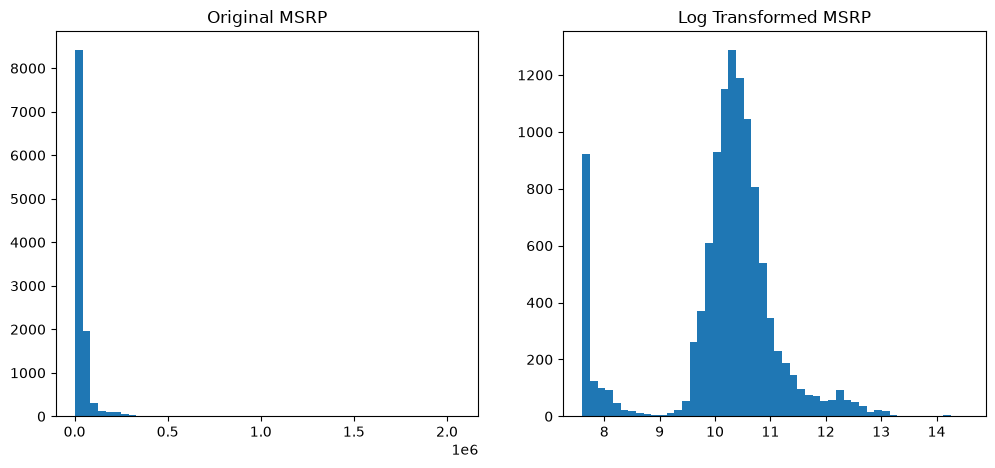

Original Skewness: 11.609709303878942
Log Skewness: -0.9295930975696736


In [76]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df['MSRP'], bins=50)
plt.title('Original MSRP')

plt.subplot(1, 2, 2)
plt.hist(np.log1p(df['MSRP']), bins=50)
plt.title('Log Transformed MSRP')

plt.show()

print("Original Skewness:", df['MSRP'].skew())
print("Log Skewness:", np.log1p(df['MSRP']).skew())

In [78]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df.drop(columns=['MSRP'])

X = pd.get_dummies(
    X,
    columns=X.select_dtypes(include=['object']).columns,
    drop_first=False
)

y = np.log1p(df['MSRP'])


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

model = ExtraTreesRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

predictions_log = model.predict(X_test)

y_test_original = np.expm1(y_test)
predictions = np.expm1(predictions_log)

print("R2:", r2_score(y_test_original, predictions))
print("MAE:", mean_absolute_error(y_test_original, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test_original, predictions)))

C:\Users\DELL\AppData\Local\Temp\ipykernel_4048\1166536389.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columns=X.select_dtypes(include=['object']).columns,


R2: 0.9693482698667847
MAE: 3283.561161145327
RMSE: 12186.490534695997


In [79]:
from sklearn.model_selection import GroupShuffleSplit

X = df.drop(columns=['MSRP'])

cat_cols = X.select_dtypes(
    include=['object', 'str', 'category']
).columns

X = pd.get_dummies(X, columns=cat_cols)

y = df['MSRP']

groups = pd.util.hash_pandas_object(
    X,
    index=False
)

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print(
    "Common groups:",
    len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
)

Train: (8900, 222)
Test: (2299, 222)
Common groups: 0


In [80]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

model = ExtraTreesRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("R2:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2: 0.9797084232586536
MAE: 2834.84133303731
RMSE: 10718.51282862387


In [81]:
y_train_pred = model.predict(X_train)

print("Train R2:", r2_score(y_train, y_train_pred))
print("Test R2:", r2_score(y_test, y_pred))

print("Train MAE:", mean_absolute_error(y_train, y_train_pred))
print("Test MAE:", mean_absolute_error(y_test, y_pred))

Train R2: 0.997263032504443
Test R2: 0.9797084232586536
Train MAE: 1435.9379819868025
Test MAE: 2834.84133303731


In [82]:
results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

results['Error'] = abs(
    results['Actual'] - results['Predicted']
)

print(
    results.sort_values(
        'Error',
        ascending=False
    ).head(15)
)

        Actual     Predicted          Error
10661  2065902  1.705769e+06  360133.000000
10662  1500000  1.705769e+06  205769.000000
6001   1382750  1.257896e+06  124854.000000
580     205840  3.015598e+05   95719.845000
7812    199495  1.105898e+05   88905.205714
678     506500  4.338100e+05   72690.000000
9096    480000  4.158952e+05   64104.815000
4417    234945  1.760869e+05   58858.113333
579     248500  3.067940e+05   58293.975000
585     184900  2.364738e+05   51573.753333
7810    144995  9.689693e+04   48098.065060
6239    133205  8.730291e+04   45902.085000
7808    139995  9.689693e+04   43098.065060
10416   234260  1.943347e+05   39925.330000
8272    247900  2.198769e+05   28023.150000


هو كا كويس في كل العربات معدا ال luxury


In [83]:
error_analysis = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

error_analysis['Absolute_Error'] = abs(
    error_analysis['Actual'] -
    error_analysis['Predicted']
)

error_analysis['Price_Category'] = pd.cut(
    error_analysis['Actual'],
    bins=[0, 25000, 50000, 100000, 300000, float('inf')],
    labels=[
        'Budget',
        'Mid-Range',
        'Premium',
        'Luxury',
        'Super Luxury'
    ]
)

category_results = error_analysis.groupby(
    'Price_Category',
    observed=True
).agg(
    Count=('Actual', 'count'),
    MAE=('Absolute_Error', 'mean'),
    Average_Actual=('Actual', 'mean')
)

print(category_results)

                Count           MAE  Average_Actual
Price_Category                                     
Budget            820    978.356699    14436.057317
Mid-Range        1072   2342.553977    34888.121269
Premium           276   3825.368450    67142.557971
Luxury            115  10605.914808   176780.017391
Super Luxury       16  58021.748281   617339.187500
